# Лабораторная работа 2. Классификация и нейронные сети

**Датасет:** Heart Disease, клиника Кливленда, UCI Machine Learning Repository, dataset 45.
**Источник файла:** `processed.cleveland.data` из того же репозитория, 14 признаков, которыми пользовались в опубликованных экспериментах.
**Цель:** сравнить пять семейств классификаторов из scikit-learn, подобрать их параметры и отдельно обучить нейронную сеть в TensorFlow с логами TensorBoard.

Положительный класс везде один: болезнь есть. Так precision, recall и ROC-AUC читаются напрямую. В исходном поле `num` степень болезни записана от 0 до 4; значения 1–4 склеены в «болезнь есть». Именно так устроены классические эксперименты на этом файле: классов 3 и 4 слишком мало (35 и 13 человек), чтобы честно учить пять методов и сеть на пяти классах.

Запускать тетрадь из папки `lab2`, интерпретатор `lab2/.venv/bin/python`.


## 0. Что сравниваем

Пять методов из задания:

1. **Наивный Байес** считает признаки независимыми при известном классе. Четыре варианта из формулировки отличаются тем, какое распределение они предполагают: нормальное (`GaussianNB`), счётчики (`MultinomialNB`), то же с поправкой на частый класс (`ComplementNB`) и бинарные флаги (`BernoulliNB`).
2. **Дерево решений** режет пространство вопросами «признак меньше порога?».
3. **Линейный дискриминантный анализ (LDA)** проводит прямую границу между классами. Он предполагает, что классы — нормальные облака с общей формой.
4. **Метод опорных векторов (SVM)** ищет границу с максимальным зазором. Линейное ядро даёт прямую, RBF — кривую.
5. **k ближайших соседей** отдаёт класс большинства среди k самых похожих пациентов обучающей выборки.

Дальше те же пациенты идут в небольшую сеть TensorFlow. Качество всех моделей — accuracy, precision, recall, F1 и AUC-ROC. Модель для отчёта выбирается по F1 на кросс-валидации: это баланс «не пропустить больного» и «не назвать больным здорового». Тестовые 20% в подборе не участвуют.

Случайность зафиксирована: `random_state=42`.


In [1]:
import os
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.naive_bayes import BernoulliNB, ComplementNB, GaussianNB, MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import Binarizer, MinMaxScaler, OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

ROOT = Path.cwd()
if not (ROOT / "requirements.txt").exists() and (ROOT / "lab2" / "requirements.txt").exists():
    ROOT = ROOT / "lab2"
DATA_PATH = ROOT / "data" / "cleveland_heart.csv"
FIG_DIR = ROOT / "figures"
RES_DIR = ROOT / "results"
LOG_DIR = ROOT / "logs"
for folder in (FIG_DIR, RES_DIR, LOG_DIR):
    folder.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.bbox"] = "tight"
plt.rcParams["axes.titlesize"] = 12

SEED = 42
TEST_SIZE = 0.2
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
np.random.seed(SEED)

NUMERIC = ["age", "trestbps", "chol", "thalach", "oldpeak"]
BINARY = ["sex", "fbs", "exang"]
CATEGORICAL = ["cp", "restecg", "slope", "ca", "thal"]
FEATURES = NUMERIC + BINARY + CATEGORICAL


## 1. Загрузка

Файл `data/cleveland_heart.csv` — обработанная выборка Cleveland Clinic Foundation: 303 пациента и 13 признаков плюс степень болезни `num`. Пропуски в исходном файле записаны знаком `?`, здесь они пустые поля. Авторы данных: Andras Janosi, William Steinbrunn, Matthias Pfisterer, Robert Detrano. Венгерская, швейцарская и лонг-бичская таблицы из того же архива в работу не входят: там гораздо больше пропусков, а опубликованные эксперименты шли по Кливленду.

Признаки:

| Столбец | Смысл |
| --- | --- |
| age | возраст, годы |
| sex | пол: 1 мужчина, 0 женщина |
| cp | боль в груди: 1 типичная стенокардия, 2 атипичная, 3 неангинальная, 4 бессимптомная |
| trestbps | давление в покое, мм рт. ст. |
| chol | холестерин, мг/дл |
| fbs | сахар натощак выше 120 мг/дл |
| restecg | ЭКГ в покое: 0 норма, 1 аномалия ST-T, 2 гипертрофия |
| thalach | максимальный пульс на нагрузке |
| exang | стенокардия на нагрузке |
| oldpeak | депрессия ST относительно покоя |
| slope | наклон пика ST: 1 вверх, 2 плоский, 3 вниз |
| ca | число крупных сосудов (0–3), которые видно при флюороскопии |
| thal | сцинтиграфия: 3 норма, 6 фиксированный дефект, 7 обратимый дефект |
| num | степень болезни 0–4, в модели не подаётся |


In [2]:
df = pd.read_csv(DATA_PATH)
df["disease"] = (df["num"] > 0).astype(int)
print(f"Файл: {DATA_PATH}")
print(f"Размер: {df.shape[0]} строк, {df.shape[1]} столбцов")
print("Пропуски:")
print(df[FEATURES].isna().sum().to_string())
df.head()


Файл: /Users/dmitrijkedrov/Documents/NSTU/sem7/ai/lab2/data/cleveland_heart.csv
Размер: 303 строк, 15 столбцов
Пропуски:
age         0
trestbps    0
chol        0
thalach     0
oldpeak     0
sex         0
fbs         0
exang       0
cp          0
restecg     0
slope       0
ca          4
thal        2


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,disease
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0,0


## 2. Первичный анализ

Смотрим баланс классов и то, какие признаки вообще отделяют больных. Пунктир на столбцах — доля больных во всей выборке, 139 из 303, то есть 45.9%.


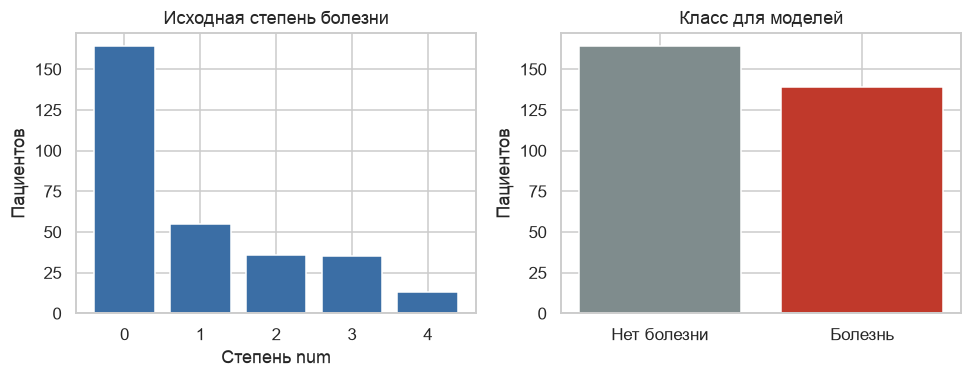

disease
нет     164
есть    139


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
severity = df["num"].value_counts().sort_index()
axes[0].bar(severity.index.astype(int).astype(str), severity.values, color="#3b6ea5")
axes[0].set_xlabel("Степень num")
axes[0].set_ylabel("Пациентов")
axes[0].set_title("Исходная степень болезни")
binary = df["disease"].value_counts().sort_index()
axes[1].bar(["Нет болезни", "Болезнь"], binary.values, color=["#7f8c8d", "#c0392b"])
axes[1].set_ylabel("Пациентов")
axes[1].set_title("Класс для моделей")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_target.png")
plt.show()
print(df["disease"].value_counts().rename({0: "нет", 1: "есть"}).to_string())


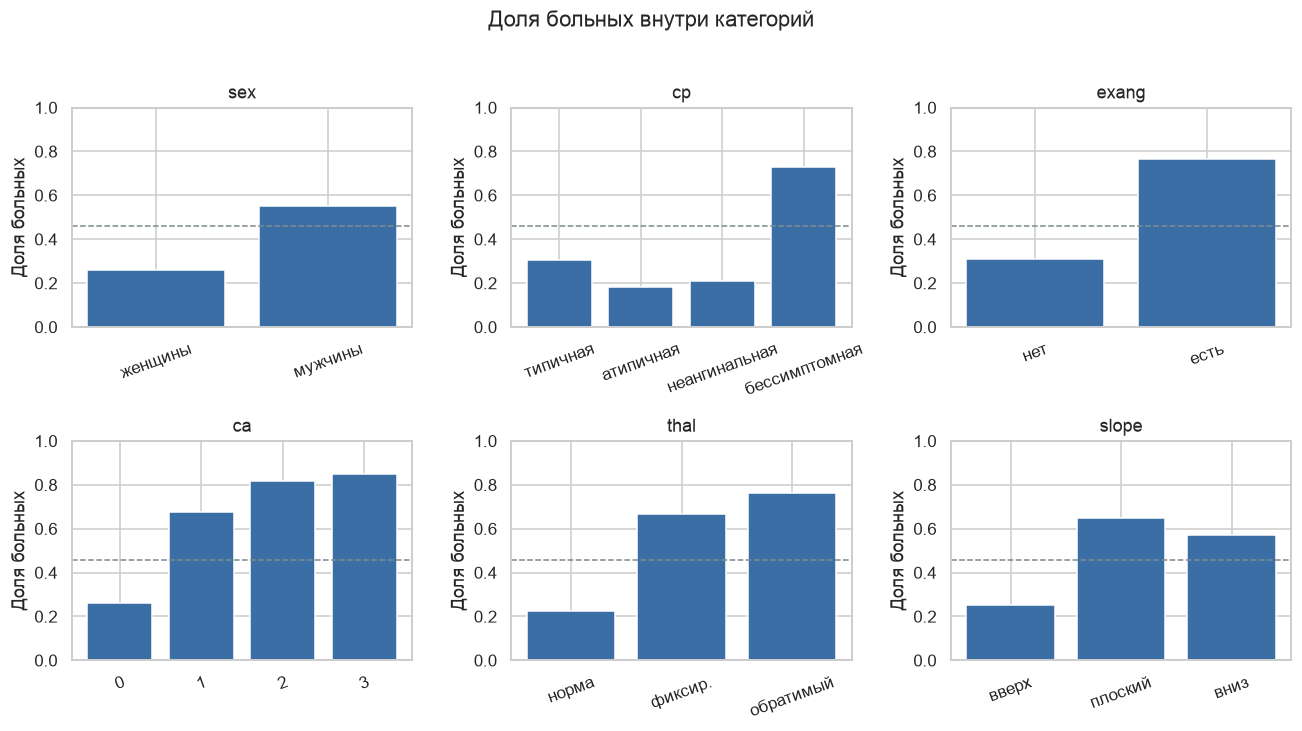

In [4]:
category_labels = {
    "sex": {0: "женщины", 1: "мужчины"},
    "cp": {1: "типичная", 2: "атипичная", 3: "неангинальная", 4: "бессимптомная"},
    "exang": {0: "нет", 1: "есть"},
    "ca": {0: "0", 1: "1", 2: "2", 3: "3"},
    "thal": {3: "норма", 6: "фиксир.", 7: "обратимый"},
    "slope": {1: "вверх", 2: "плоский", 3: "вниз"},
}
base_rate = float(df["disease"].mean())
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
for ax, column in zip(axes.ravel(), category_labels):
    grouped = df.dropna(subset=[column]).groupby(column)["disease"].agg(["mean", "size"])
    labels = [category_labels[column].get(value, str(value)) for value in grouped.index]
    ax.bar(labels, grouped["mean"], color="#3b6ea5")
    ax.axhline(base_rate, color="#7f8c8d", ls="--", lw=1)
    ax.set_ylim(0, 1)
    ax.set_ylabel("Доля больных")
    ax.set_title(column)
    ax.tick_params(axis="x", rotation=20)
fig.suptitle("Доля больных внутри категорий", y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_category_rates.png")
plt.show()


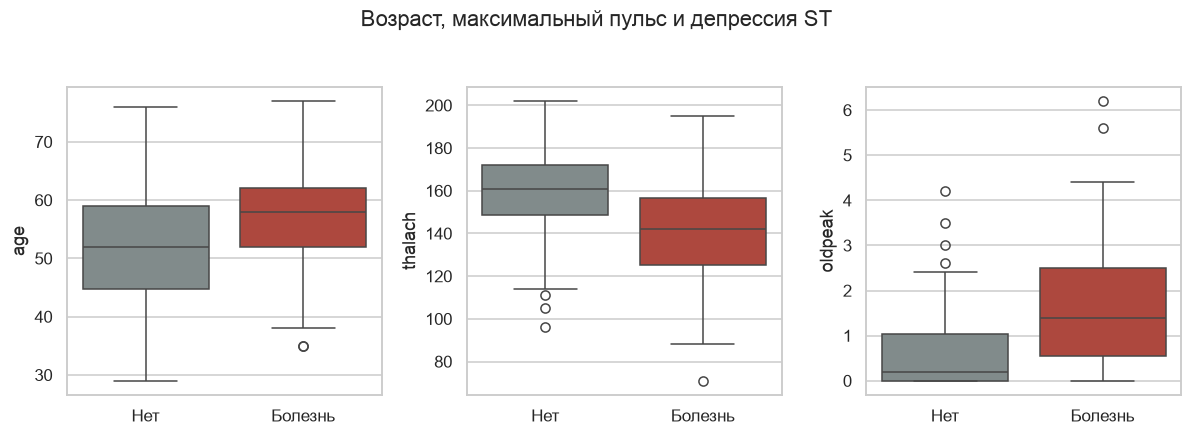

,Нет болезни,Болезнь
age,52.59,56.63
trestbps,129.25,134.57
chol,242.64,251.47
thalach,158.38,139.26
oldpeak,0.59,1.57


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
for ax, column in zip(axes, ["age", "thalach", "oldpeak"]):
    sns.boxplot(
        data=df,
        x="disease",
        y=column,
        hue="disease",
        ax=ax,
        palette=["#7f8c8d", "#c0392b"],
        legend=False,
    )
    ax.set_xlabel("")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Нет", "Болезнь"])
fig.suptitle("Возраст, максимальный пульс и депрессия ST", y=1.04)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_continuous.png")
plt.show()

summary = df.groupby("disease")[NUMERIC].mean().T
summary.columns = ["Нет болезни", "Болезнь"]
summary.round(2)


**Что видно до моделей.** Классы почти равны: 164 здоровых и 139 больных. Accuracy около 0.54 уже даёт правило «все здоровы», поэтому само по себе число 0.75 ещё ничего не значит, пока рядом нет recall и F1.

Сильнее всего болезнь связана не с холестерином. Бессимптомный тип боли (`cp = 4`) встречается у 144 человек, и больны 73% из них; при атипичной боли — 18%. Это не вывод «отсутствие симптомов опасно»: в эту клинику попадали люди, уже направленные на ангиографию, и код 4 означает особый тип наблюдения, а не здоровье. Стенокардия на нагрузке поднимает долю больных с 31% до 77%. Ноль окрашенных сосудов — 26% больных, три сосуда — 85%. Нормальная сцинтиграфия (`thal = 3`) — 22% больных, обратимый дефект — 76%.

Из непрерывных признаков расходятся максимальный пульс (158 у здоровых против 139 у больных) и депрессия ST (0.59 против 1.57). Возраст сдвигается слабее, 53 против 57 лет. Сахар натощак почти не разделяет классы: 45% против 49%. У `restecg = 1` всего 4 человека, долю по ним обсуждать нельзя.

Пропуски точечные: 4 в `ca` и 2 в `thal`. Строки не выбрасываем, пропуски заполняются внутри обучения.


## 3. Предобработка и разбиение

Разбиение 80/20 стратифицированное, чтобы в тесте сохранилась доля больных. Кросс-валидация — пять стратифицированных блоков внутри обучающих 80%.

Заполнение пропусков стоит внутри пайплайна и учится заново на каждом блоке. Иначе медиана сосудов из тестовых пациентов попала бы в обучение.

- `ca` и `thal` — категории с пропуском, заполняются самым частым значением и разворачиваются в индикаторы. У сосудов четыре значения, среднее 1.2 сосуда не бывает, поэтому медиана здесь хуже моды.
- `sex`, `fbs`, `exang` уже флаги 0/1.
- Возраст, давление, холестерин, пульс и `oldpeak` заполняются медианой.

Масштаб зависит от метода и тоже сидит в пайплайне:

- дереву масштаб не нужен;
- Байесу с нормальным распределением, LDA, SVM и kNN числовые признаки стандартизируются;
- MultinomialNB и ComplementNB не принимают отрицательные числа, поэтому для них шкала сжимается в отрезок от 0 до 1, а не в z-оценки;
- BernoulliNB после этого ещё режет каждый признак пополам: выше середины обучающего диапазона — 1, иначе 0. Индикаторы 0/1 при таком пороге не меняются.


In [6]:
X = df[FEATURES]
y = df["disease"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y
)
print(f"Обучение: {len(X_train)}, доля больных {y_train.mean():.3f}")
print(f"Тест:     {len(X_test)}, доля больных {y_test.mean():.3f}")


def build_preprocessor(scale: str) -> ColumnTransformer:
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale == "standard":
        numeric_steps.append(("scale", StandardScaler()))
    elif scale == "minmax":
        numeric_steps.append(("scale", MinMaxScaler()))
    return ColumnTransformer([
        ("num", Pipeline(numeric_steps), NUMERIC),
        ("bin", SimpleImputer(strategy="most_frequent"), BINARY),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), CATEGORICAL),
    ])


def fit_search(pipeline: Pipeline, grid: dict) -> GridSearchCV:
    search = GridSearchCV(
        pipeline,
        grid,
        scoring="f1",
        cv=CV,
        refit=True,
        return_train_score=True,
        n_jobs=1,
        error_score="raise",
    )
    search.fit(X_train, y_train)
    return search


def positive_scores(estimator, features) -> np.ndarray:
    # У SVM в актуальном scikit-learn вероятность считается отдельно и помечена
    # как устаревающая. Для ROC достаточно отступа от границы, он уже ранжирует.
    if isinstance(estimator.named_steps["model"], SVC):
        return estimator.decision_function(features)
    proba = estimator.predict_proba(features)
    index = list(estimator.classes_).index(1)
    return proba[:, index]


def score_model(name: str, estimator, f1_cv: float, params: dict) -> dict:
    pred = estimator.predict(X_test)
    scores = positive_scores(estimator, X_test)
    roc_store[name] = scores
    return {
        "Модель": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, scores),
        "F1_CV": f1_cv,
        "Параметры": params,
    }


roc_store = {}


Обучение: 242, доля больных 0.459
Тест:     61, доля больных 0.459


## 4. Наивный Байес: четыре варианта

Сетка для нормального варианта — `var_smoothing`, добавка к дисперсии, чтобы редкий признак не получал нулевую дисперсию. Для трёх остальных — `alpha`, сила сглаживания вероятностей. Чем больше `alpha`, тем ближе вероятности признаков к «у всех классов одинаково» и тем слабее модель реагирует на выборку.

Метрика подбора — средний F1 по пяти блокам.


In [7]:
nb_specs = [
    (
        "GaussianNB",
        Pipeline([("prep", build_preprocessor("standard")), ("model", GaussianNB())]),
        {"model__var_smoothing": np.logspace(-12, 0, 13)},
    ),
    (
        "MultinomialNB",
        Pipeline([("prep", build_preprocessor("minmax")), ("model", MultinomialNB())]),
        {"model__alpha": np.logspace(-2, 2, 9)},
    ),
    (
        "ComplementNB",
        Pipeline([("prep", build_preprocessor("minmax")), ("model", ComplementNB())]),
        {"model__alpha": np.logspace(-2, 2, 9)},
    ),
    (
        "BernoulliNB",
        Pipeline([
            ("prep", build_preprocessor("minmax")),
            ("binarize", Binarizer(threshold=0.5)),
            ("model", BernoulliNB()),
        ]),
        {"model__alpha": np.logspace(-2, 2, 9)},
    ),
]
nb_searches = {name: fit_search(pipe, grid) for name, pipe, grid in nb_specs}
nb_table = pd.DataFrame([
    {
        "Вариант": name,
        "F1_CV": search.best_score_,
        "Параметр": search.best_params_,
    }
    for name, search in nb_searches.items()
]).sort_values("F1_CV", ascending=False)
nb_table.to_csv(RES_DIR / "nb_variants.csv", index=False)
nb_table.round(4)


,Вариант,F1_CV,Параметр
3,BernoulliNB,0.8233,{'model__alpha': 3.1622776601683795}
2,ComplementNB,0.8220,{'model__alpha': 100.0}
1,MultinomialNB,0.8148,{'model__alpha': 1.0}
0,GaussianNB,0.8137,{'model__var_smoothing': 0.1}


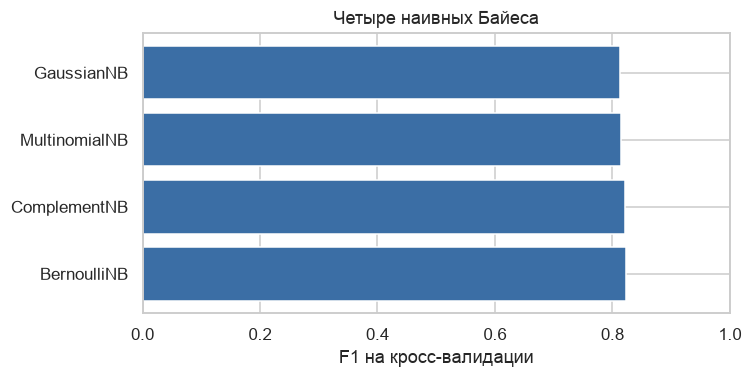

Дальше в общем сравнении участвует BernoulliNB


In [8]:
fig, ax = plt.subplots(figsize=(7, 3.6))
order = nb_table["Вариант"].tolist()
ax.barh(order, nb_table["F1_CV"], color="#3b6ea5")
ax.set_xlabel("F1 на кросс-валидации")
ax.set_xlim(0, 1)
ax.set_title("Четыре наивных Байеса")
fig.tight_layout()
fig.savefig(FIG_DIR / "04_nb_variants.png")
plt.show()

best_nb_name = nb_table.iloc[0]["Вариант"]
best_nb = nb_searches[best_nb_name]
print("Дальше в общем сравнении участвует", best_nb_name)


## 5. Дерево, LDA, SVM и соседи

У дерева сетка — глубина от 1 до 10 и минимум объектов в листе 1, 5 или 10. Глубокое дерево с листом из одного пациента запоминает обучение; ограничение глубины это обрывает.

У LDA один содержательный параметр: `shrinkage`, сжатие ковариационной матрицы к диагональной. Ноль — обычный LDA, единица — признаки считаются независимыми. Решатель `lsqr`, потому что сжатие в scikit-learn доступно ему, а не решателю по умолчанию.

У SVM сравниваются линейное ядро и RBF. `C` — цена ошибки: маленькое `C` шире зазор и проще граница, большое `C` старается не ошибаться на обучении. Для RBF ещё перебирается `gamma`, ширина гауссова холма вокруг опорного вектора.

У соседей перебираются k от 1 до 29 и голосование: обычное большинство или веса по расстоянию. k = 1 копирует класс ближайшего пациента и почти всегда запоминает выборку.


In [9]:
tree_search = fit_search(
    Pipeline([
        ("prep", build_preprocessor("none")),
        ("model", DecisionTreeClassifier(random_state=SEED)),
    ]),
    {"model__max_depth": list(range(1, 11)), "model__min_samples_leaf": [1, 5, 10]},
)
lda_search = fit_search(
    Pipeline([
        ("prep", build_preprocessor("standard")),
        ("model", LinearDiscriminantAnalysis(solver="lsqr")),
    ]),
    {"model__shrinkage": np.linspace(0, 1, 11)},
)
svm_search = fit_search(
    Pipeline([
        ("prep", build_preprocessor("standard")),
        ("model", SVC(random_state=SEED)),
    ]),
    [
        {"model__kernel": ["linear"], "model__C": np.logspace(-2, 2, 7)},
        {
            "model__kernel": ["rbf"],
            "model__C": np.logspace(-2, 2, 7),
            "model__gamma": ["scale", 0.1, 1],
        },
    ],
)
knn_search = fit_search(
    Pipeline([
        ("prep", build_preprocessor("standard")),
        ("model", KNeighborsClassifier()),
    ]),
    {"model__n_neighbors": list(range(1, 31, 2)), "model__weights": ["uniform", "distance"]},
)
for title, search in [
    ("Дерево", tree_search),
    ("LDA", lda_search),
    ("SVM", svm_search),
    ("kNN", knn_search),
]:
    print(f"{title}: F1_CV={search.best_score_:.3f}, {search.best_params_}")


Дерево: F1_CV=0.770, {'model__max_depth': 3, 'model__min_samples_leaf': 10}
LDA: F1_CV=0.830, {'model__shrinkage': np.float64(0.4)}
SVM: F1_CV=0.813, {'model__C': np.float64(0.21544346900318834), 'model__gamma': 'scale', 'model__kernel': 'rbf'}
kNN: F1_CV=0.819, {'model__n_neighbors': 5, 'model__weights': 'uniform'}


## 6. Как параметры двигают качество

Кривые построены по кросс-валидации на обучении. Для каждого метода остальные параметры зафиксированы на значении, которое выбрала сетка, и меняется один. Пунктир — F1 на обучающих блоках, сплошная линия — на проверочном блоке. Где пунктир уходит вверх, а сплошная линия падает, модель начинает запоминать конкретных пациентов.


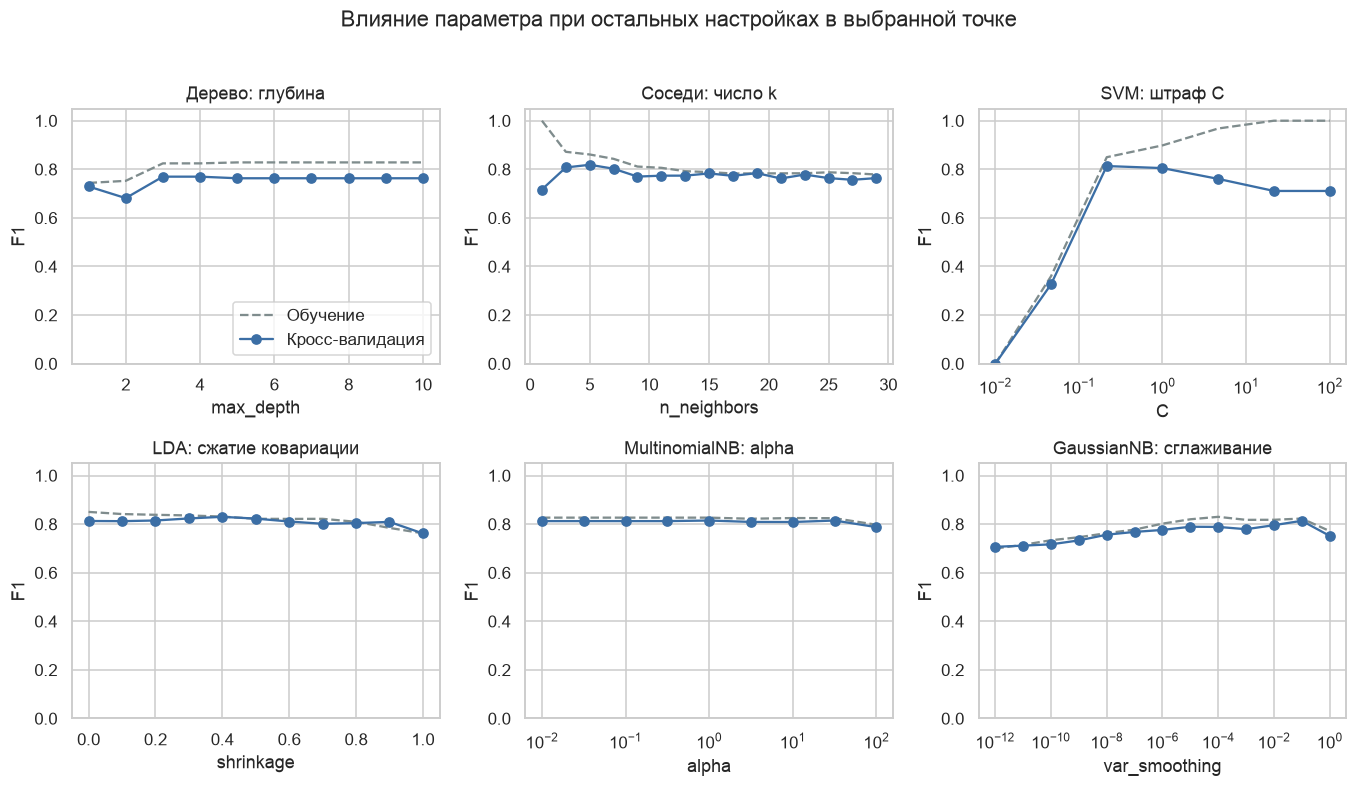

In [10]:
def values_match(left, right) -> bool:
    numeric = (int, float, np.integer, np.floating)
    if isinstance(left, numeric) and isinstance(right, numeric) and not isinstance(left, bool):
        return bool(np.isclose(float(left), float(right), rtol=1e-6, atol=1e-8))
    return left == right


def slice_curve(search: GridSearchCV, vary: str):
    best = search.best_params_
    rows = []
    for params, train_score, test_score in zip(
        search.cv_results_["params"],
        search.cv_results_["mean_train_score"],
        search.cv_results_["mean_test_score"],
    ):
        if vary not in params:
            continue
        fixed_ok = all(
            key == vary or key not in params or values_match(params[key], value)
            for key, value in best.items()
        )
        if fixed_ok:
            rows.append((params[vary], train_score, test_score))
    rows.sort(key=lambda item: float(item[0]) if not isinstance(item[0], str) else item[0])
    xs = [item[0] for item in rows]
    train = [item[1] for item in rows]
    test = [item[2] for item in rows]
    return xs, train, test


def draw_curve(ax, search, vary, title, log_x=False):
    xs, train, test = slice_curve(search, vary)
    xplot = np.arange(len(xs)) if any(isinstance(x, str) for x in xs) else np.array(xs, dtype=float)
    ax.plot(xplot, train, ls="--", color="#7f8c8d", label="Обучение")
    ax.plot(xplot, test, color="#3b6ea5", marker="o", label="Кросс-валидация")
    if log_x:
        ax.set_xscale("log")
    if any(isinstance(x, str) for x in xs):
        ax.set_xticks(xplot)
        ax.set_xticklabels(xs)
    ax.set_title(title)
    ax.set_ylim(0, 1.05)
    ax.set_xlabel(vary.split("__")[-1])
    ax.set_ylabel("F1")


fig, axes = plt.subplots(2, 3, figsize=(12.5, 7))
draw_curve(axes[0, 0], tree_search, "model__max_depth", "Дерево: глубина")
draw_curve(axes[0, 1], knn_search, "model__n_neighbors", "Соседи: число k")
draw_curve(axes[0, 2], svm_search, "model__C", "SVM: штраф C", log_x=True)
draw_curve(axes[1, 0], lda_search, "model__shrinkage", "LDA: сжатие ковариации")
draw_curve(axes[1, 1], nb_searches["MultinomialNB"], "model__alpha", "MultinomialNB: alpha", log_x=True)
draw_curve(axes[1, 2], nb_searches["GaussianNB"], "model__var_smoothing", "GaussianNB: сглаживание", log_x=True)
axes[0, 0].legend(loc="lower right")
fig.suptitle("Влияние параметра при остальных настройках в выбранной точке", y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "05_param_effects.png")
plt.show()


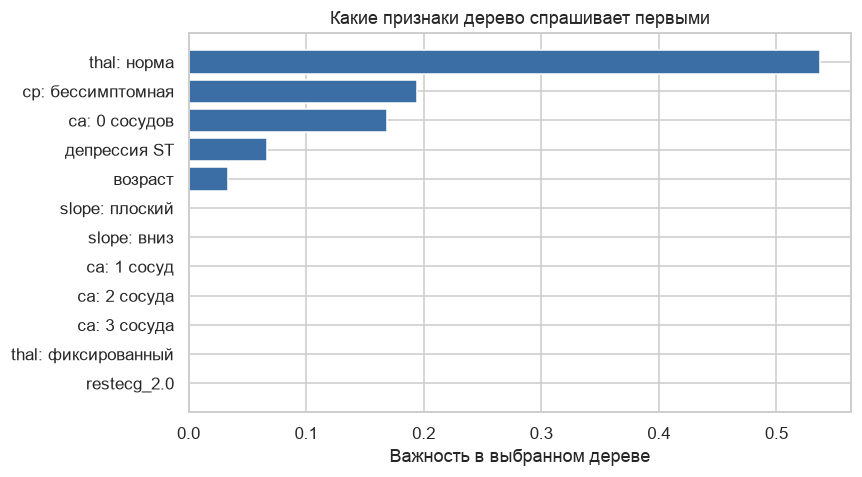

In [11]:
tree = tree_search.best_estimator_
pretty = {
    "thal_3.0": "thal: норма",
    "thal_6.0": "thal: фиксированный",
    "thal_7.0": "thal: обратимый",
    "cp_4.0": "cp: бессимптомная",
    "cp_3.0": "cp: неангинальная",
    "cp_2.0": "cp: атипичная",
    "cp_1.0": "cp: типичная",
    "ca_0.0": "ca: 0 сосудов",
    "ca_1.0": "ca: 1 сосуд",
    "ca_2.0": "ca: 2 сосуда",
    "ca_3.0": "ca: 3 сосуда",
    "oldpeak": "депрессия ST",
    "age": "возраст",
    "thalach": "максимальный пульс",
    "chol": "холестерин",
    "trestbps": "давление",
    "slope_2.0": "slope: плоский",
    "slope_3.0": "slope: вниз",
    "slope_1.0": "slope: вверх",
    "exang_1.0": "стенокардия на нагрузке",
    "sex_1.0": "мужчины",
}
raw_names = [name.split("__", 1)[-1] for name in tree.named_steps["prep"].get_feature_names_out()]
importances = pd.Series(
    tree.named_steps["model"].feature_importances_,
    index=[pretty.get(name, name) for name in raw_names],
).sort_values(ascending=False)
top = importances.head(12).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top.index, top.values, color="#3b6ea5")
ax.set_xlabel("Важность в выбранном дереве")
ax.set_title("Какие признаки дерево спрашивает первыми")
fig.tight_layout()
fig.savefig(FIG_DIR / "06_tree_importance.png")
plt.show()


## 7. Качество пяти методов на тесте

Параметры выше выбраны по обучающей кросс-валидации. Таблица ниже — один проход по тестовым 20%. Precision и recall считаются для класса «болезнь есть»: precision — доля настоящих больных среди тех, кого модель назвала больными; recall — какую долю настоящих больных модель нашла.

$$\mathrm{Precision} = \frac{TP}{TP+FP}, \quad \mathrm{Recall} = \frac{TP}{TP+FN}, \quad F1 = \frac{2 \cdot \mathrm{Precision} \cdot \mathrm{Recall}}{\mathrm{Precision}+\mathrm{Recall}}.$$

ROC-AUC не зависит от порога 0.5. Это вероятность, что случайный больной получит оценку выше случайного здорового. Диагональ на графике — бесполезный ранжировщик, AUC 0.5.


In [12]:
classical = [
    score_model(f"Байес ({best_nb_name})", best_nb.best_estimator_, best_nb.best_score_, best_nb.best_params_),
    score_model("Дерево", tree_search.best_estimator_, tree_search.best_score_, tree_search.best_params_),
    score_model("LDA", lda_search.best_estimator_, lda_search.best_score_, lda_search.best_params_),
    score_model("SVM", svm_search.best_estimator_, svm_search.best_score_, svm_search.best_params_),
    score_model("kNN", knn_search.best_estimator_, knn_search.best_score_, knn_search.best_params_),
]
metrics_classical = pd.DataFrame(classical)

majority = int(y_train.mode().iloc[0])
majority_pred = np.full(len(y_test), majority)
always_sick = np.ones(len(y_test), dtype=int)
print(f"База «все как большинство обучения» ({majority}): accuracy {accuracy_score(y_test, majority_pred):.3f}")
print(
    "База «все больны»:",
    f"accuracy {accuracy_score(y_test, always_sick):.3f},",
    f"precision {precision_score(y_test, always_sick):.3f},",
    f"recall {recall_score(y_test, always_sick):.3f},",
    f"F1 {f1_score(y_test, always_sick):.3f}",
)
metrics_classical.round(3)


База «все как большинство обучения» (0): accuracy 0.541
База «все больны»: accuracy 0.459, precision 0.459, recall 1.000, F1 0.629


,Модель,Accuracy,Precision,Recall,F1,ROC_AUC,F1_CV,Параметры
0,Байес (BernoulliNB),0.869,0.833,0.893,0.862,0.958,0.823,{'model__alpha': 3.1622776601683795}
1,Дерево,0.869,0.857,0.857,0.857,0.871,0.770,"{'model__max_depth': 3, 'model__min_samples_le..."
2,LDA,0.885,0.839,0.929,0.881,0.968,0.830,{'model__shrinkage': 0.4}
3,SVM,0.902,0.867,0.929,0.897,0.961,0.813,"{'model__C': 0.21544346900318834, 'model__gamm..."
4,kNN,0.918,0.897,0.929,0.912,0.934,0.819,"{'model__n_neighbors': 5, 'model__weights': 'u..."


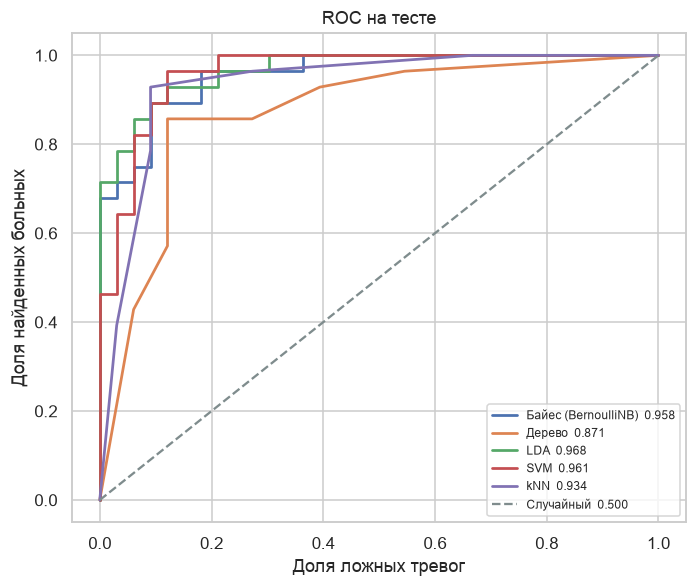

In [13]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for name, scores in roc_store.items():
    fpr, tpr, _ = roc_curve(y_test, scores)
    ax.plot(fpr, tpr, lw=1.8, label=f"{name}  {roc_auc_score(y_test, scores):.3f}")
ax.plot([0, 1], [0, 1], ls="--", color="#7f8c8d", label="Случайный  0.500")
ax.set_xlabel("Доля ложных тревог")
ax.set_ylabel("Доля найденных больных")
ax.set_title("ROC на тесте")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "07_roc_classical.png")
plt.show()


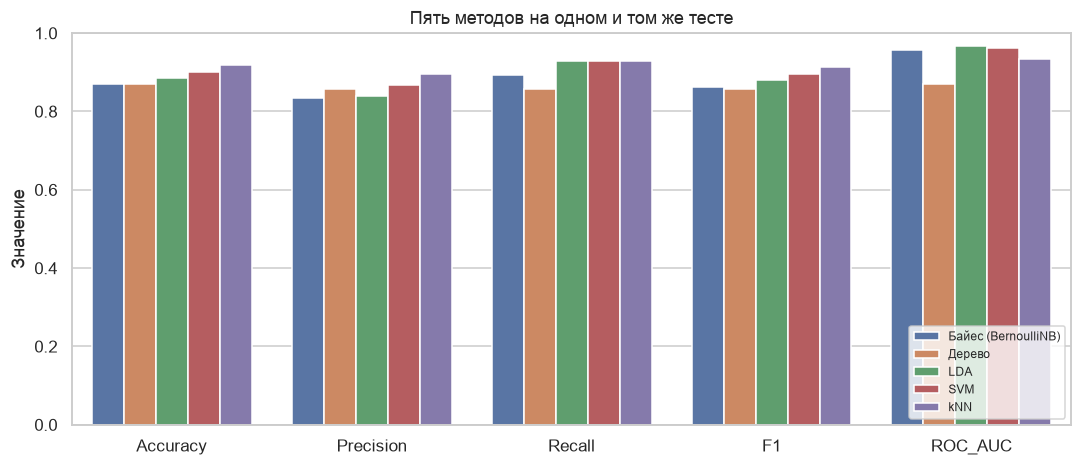

In [14]:
plot_df = metrics_classical.melt(
    id_vars="Модель",
    value_vars=["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"],
    var_name="Метрика",
    value_name="Значение",
)
fig, ax = plt.subplots(figsize=(10, 4.4))
sns.barplot(data=plot_df, x="Метрика", y="Значение", hue="Модель", ax=ax)
ax.set_ylim(0, 1)
ax.set_xlabel("")
ax.set_title("Пять методов на одном и том же тесте")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "08_metrics_classical.png")
plt.show()


## 8. Нейронная сеть и TensorBoard

Сеть — два полносвязных слоя с ReLU и выходной нейрон с сигмоидой. Сигмоида выдаёт оценку от 0 до 1, потеря — бинарная кросс-энтропия, оптимизатор Adam. Это прямой нелинейный классификатор: скрытый слой собирает комбинации признаков, которые одному LDA не построить.

Обучающие 80% ещё раз делятся стратифицированно: 80% из них учат веса, 20% следят за ранней остановкой и за выбором гиперпараметров. Тест по-прежнему в стороне. Из-за этого сеть видит меньше пациентов, чем дерево или SVM; на 303 строках это заметная оговорка, её нельзя прятать.

Сетка небольшая и нарочно однофакторная по смыслу графика: 8, 16 или 32 нейрона в первом слое, dropout 0 или 0.4, скорость обучения 0.001 или 0.01. Второй слой вдвое уже первого. Dropout выключает случайную долю нейронов на каждом шаге и мешает сети запомнить конкретные строки. Ранняя остановка смотрит на validation loss, терпение 10 эпох, возвращает веса лучшей эпохи. Максимум 60 эпох, пакет 16.

Каждый запуск пишет логи в `logs/`. TensorBoard читает оттуда loss, accuracy, AUC и их проверки на отложенных пациентах. Из папки `lab2`:

```bash
.venv/bin/tensorboard --logdir logs
```


In [15]:
import tensorflow as tf
from tensorflow import keras

X_fit, X_watch, y_fit, y_watch = train_test_split(
    X_train, y_train, test_size=0.2, random_state=SEED, stratify=y_train
)
nn_prep = build_preprocessor("standard")
X_fit_s = nn_prep.fit_transform(X_fit)
X_watch_s = nn_prep.transform(X_watch)
X_test_s = nn_prep.transform(X_test)
print(f"Сеть учится на {len(X_fit)}, контроль {len(X_watch)}, тест {len(X_test)}, признаков {X_fit_s.shape[1]}")


def make_network(n_features: int, hidden: int, dropout: float, learning_rate: float) -> keras.Model:
    network = keras.Sequential([
        keras.layers.Input(shape=(n_features,)),
        keras.layers.Dense(hidden, activation="relu"),
        keras.layers.Dropout(dropout),
        keras.layers.Dense(max(hidden // 2, 4), activation="relu"),
        keras.layers.Dense(1, activation="sigmoid"),
    ])
    network.compile(
        optimizer=keras.optimizers.Adam(learning_rate),
        loss="binary_crossentropy",
        metrics=["accuracy", keras.metrics.AUC(name="auc")],
    )
    return network


def train_network(hidden: int, dropout: float, learning_rate: float):
    tf.keras.utils.set_random_seed(SEED)
    run_name = f"h{hidden}_drop{dropout}_lr{learning_rate}"
    network = make_network(X_fit_s.shape[1], hidden, dropout, learning_rate)
    callbacks = [
        keras.callbacks.TensorBoard(log_dir=str(LOG_DIR / run_name), histogram_freq=0, profile_batch=0),
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
    ]
    history = network.fit(
        X_fit_s,
        y_fit,
        validation_data=(X_watch_s, y_watch),
        epochs=60,
        batch_size=16,
        callbacks=callbacks,
        verbose=0,
    )
    best_epoch = int(np.argmin(history.history["val_loss"]))
    return {
        "run": run_name,
        "hidden": hidden,
        "dropout": dropout,
        "lr": learning_rate,
        "epochs": best_epoch + 1,
        "val_loss": float(history.history["val_loss"][best_epoch]),
        "val_auc": float(history.history["val_auc"][best_epoch]),
        "val_accuracy": float(history.history["val_accuracy"][best_epoch]),
        "model": network,
        "history": history.history,
    }


nn_runs = [
    train_network(hidden, dropout, learning_rate)
    for hidden in (8, 16, 32)
    for dropout in (0.0, 0.4)
    for learning_rate in (1e-3, 1e-2)
]
nn_table = pd.DataFrame([{k: v for k, v in run.items() if k not in ("model", "history")} for run in nn_runs])
nn_table = nn_table.sort_values(["val_loss", "val_auc"], ascending=[True, False]).reset_index(drop=True)
nn_table.to_csv(RES_DIR / "nn_grid.csv", index=False)
nn_table.round(4)


Сеть учится на 193, контроль 49, тест 61, признаков 25


,run,hidden,dropout,lr,epochs,val_loss,val_auc,val_accuracy
0,h16_drop0.0_lr0.01,16,0.0,0.010,9,0.2903,0.9394,0.8776
1,h32_drop0.4_lr0.001,32,0.4,0.001,48,0.2996,0.9453,0.8163
2,h32_drop0.0_lr0.001,32,0.0,0.001,44,0.3024,0.9495,0.8367
3,h32_drop0.4_lr0.01,32,0.4,0.010,4,0.3048,0.9503,0.8571
4,h32_drop0.0_lr0.01,32,0.0,0.010,6,0.3059,0.9487,0.8571
5,h8_drop0.0_lr0.01,8,0.0,0.010,8,0.3139,0.9369,0.8367
6,h8_drop0.0_lr0.001,8,0.0,0.001,60,0.3211,0.9360,0.8571
7,h16_drop0.0_lr0.001,16,0.0,0.001,60,0.3222,0.9217,0.8367
8,h16_drop0.4_lr0.01,16,0.4,0.010,23,0.3230,0.9192,0.8571
9,h8_drop0.4_lr0.01,8,0.4,0.010,20,0.3266,0.9621,0.8776


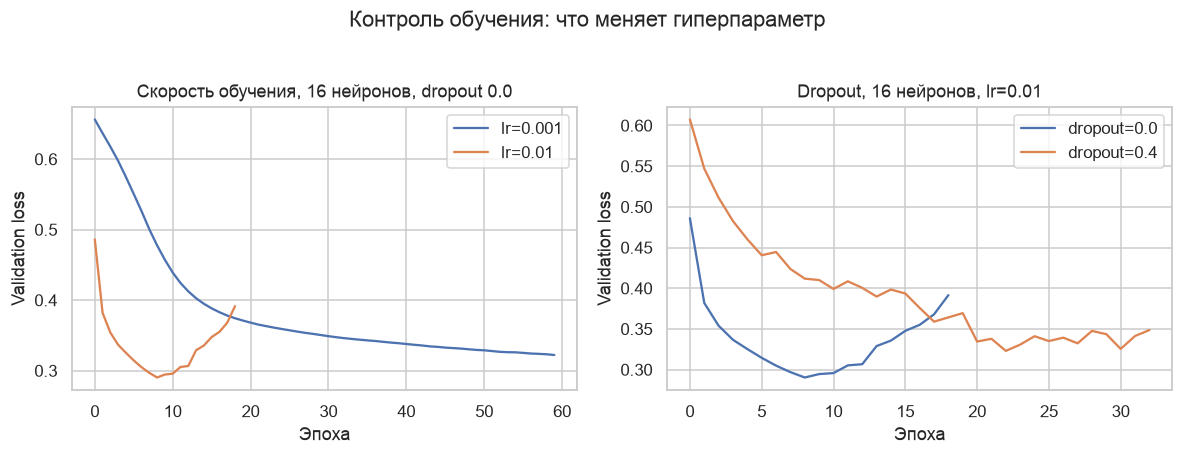

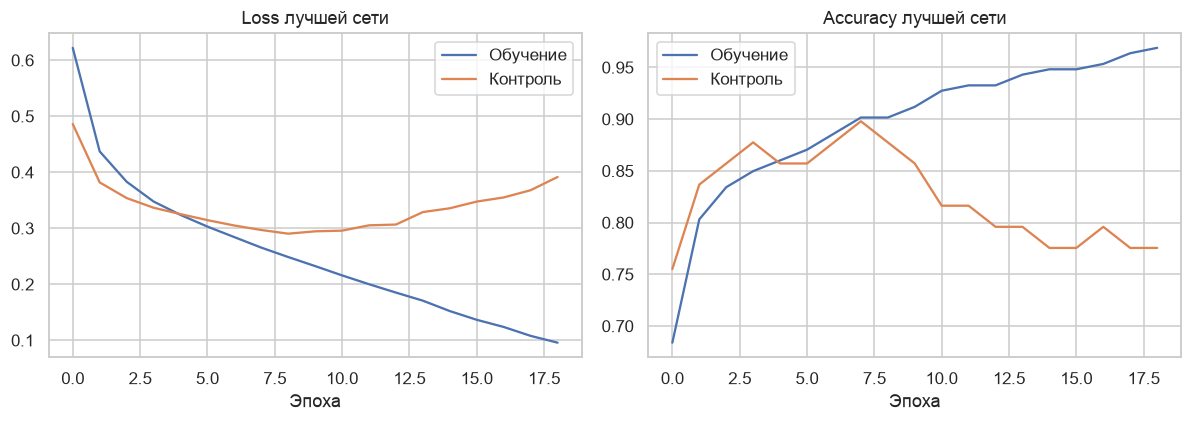

Лучший запуск по validation loss: h16_drop0.0_lr0.01 эпоха 9


In [16]:
best_nn = min(nn_runs, key=lambda run: (run["val_loss"], -run["val_auc"]))
fixed_hidden = 16
fixed_dropout = 0.0
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for run in nn_runs:
    if run["hidden"] == fixed_hidden and run["dropout"] == fixed_dropout:
        axes[0].plot(run["history"]["val_loss"], label=f"lr={run['lr']}")
    if run["hidden"] == fixed_hidden and run["lr"] == best_nn["lr"]:
        axes[1].plot(run["history"]["val_loss"], label=f"dropout={run['dropout']}")
axes[0].set_title(f"Скорость обучения, {fixed_hidden} нейронов, dropout {fixed_dropout}")
axes[1].set_title(f"Dropout, {fixed_hidden} нейронов, lr={best_nn['lr']}")
for ax in axes:
    ax.set_xlabel("Эпоха")
    ax.set_ylabel("Validation loss")
    ax.legend()
fig.suptitle("Контроль обучения: что меняет гиперпараметр", y=1.03)
fig.tight_layout()
fig.savefig(FIG_DIR / "09_nn_learning_curves.png")
plt.show()

history = best_nn["history"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history["loss"], label="Обучение")
axes[0].plot(history["val_loss"], label="Контроль")
axes[0].set_title("Loss лучшей сети")
axes[0].set_xlabel("Эпоха")
axes[1].plot(history["accuracy"], label="Обучение")
axes[1].plot(history["val_accuracy"], label="Контроль")
axes[1].set_title("Accuracy лучшей сети")
axes[1].set_xlabel("Эпоха")
for ax in axes:
    ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "10_nn_best_history.png")
plt.show()
print("Лучший запуск по validation loss:", best_nn["run"], "эпоха", best_nn["epochs"])


In [17]:
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

# TensorFlow 2.21 пишет кривые как tensors в подкаталоги train и validation.
# TensorBoard показывает их на вкладках Scalars.
event_dir = LOG_DIR / best_nn["run"] / "train"
accumulator = EventAccumulator(str(event_dir), size_guidance={"tensors": 0})
accumulator.Reload()
tags = accumulator.Tags().get("tensors", [])
print("Каталог логов:", LOG_DIR.resolve())
print("Кривые лучшего запуска:", ", ".join(tag for tag in tags if tag != "keras"))
print("Запуск из папки lab2: .venv/bin/tensorboard --logdir logs")


Каталог логов: /Users/dmitrijkedrov/Documents/NSTU/sem7/ai/lab2/logs
Кривые лучшего запуска: epoch_accuracy, epoch_auc, epoch_loss, epoch_learning_rate
Запуск из папки lab2: .venv/bin/tensorboard --logdir logs


In [18]:
nn_proba = best_nn["model"].predict(X_test_s, verbose=0).ravel()
nn_pred = (nn_proba >= 0.5).astype(int)
roc_store["Нейросеть"] = nn_proba
nn_row = {
    "Модель": "Нейросеть",
    "Accuracy": accuracy_score(y_test, nn_pred),
    "Precision": precision_score(y_test, nn_pred, zero_division=0),
    "Recall": recall_score(y_test, nn_pred, zero_division=0),
    "F1": f1_score(y_test, nn_pred, zero_division=0),
    "ROC_AUC": roc_auc_score(y_test, nn_proba),
    "F1_CV": np.nan,
    "Параметры": {
        "hidden": best_nn["hidden"],
        "dropout": best_nn["dropout"],
        "lr": best_nn["lr"],
        "epochs": best_nn["epochs"],
    },
}
metrics_all = pd.concat([metrics_classical, pd.DataFrame([nn_row])], ignore_index=True)
metrics_all.to_csv(RES_DIR / "metrics.csv", index=False)
metrics_all.drop(columns="Параметры").round(3)


,Модель,Accuracy,Precision,Recall,F1,ROC_AUC,F1_CV
0,Байес (BernoulliNB),0.869,0.833,0.893,0.862,0.958,0.823
1,Дерево,0.869,0.857,0.857,0.857,0.871,0.770
2,LDA,0.885,0.839,0.929,0.881,0.968,0.830
3,SVM,0.902,0.867,0.929,0.897,0.961,0.813
4,kNN,0.918,0.897,0.929,0.912,0.934,0.819
5,Нейросеть,0.885,0.839,0.929,0.881,0.970,NaN


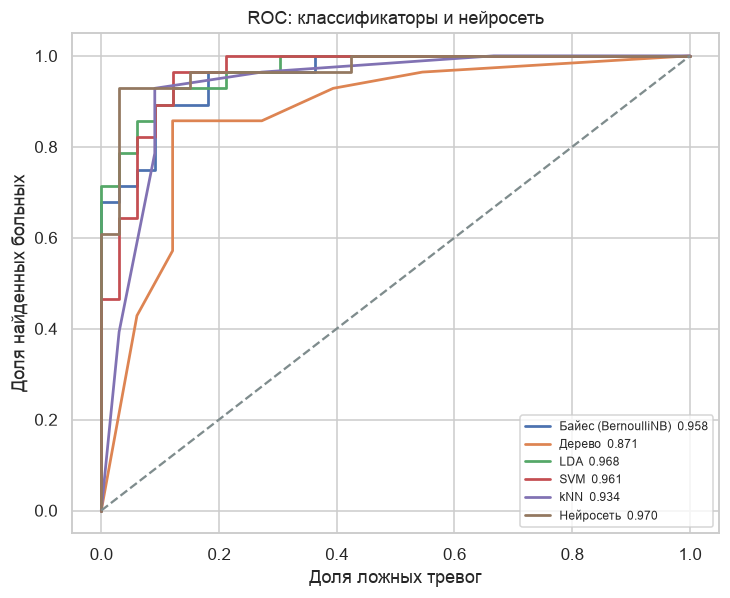

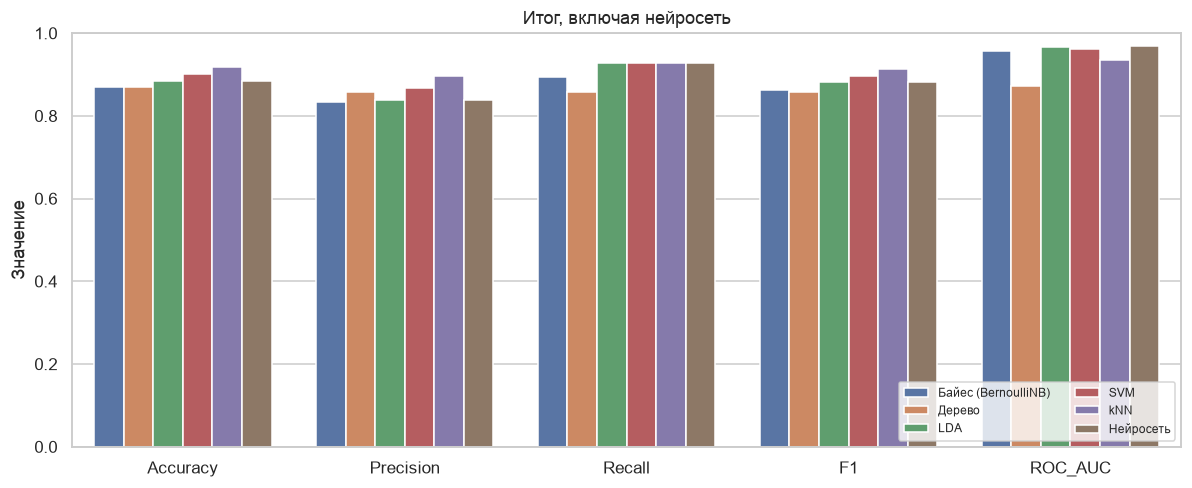

In [19]:
fig, ax = plt.subplots(figsize=(6.8, 5.6))
for name, scores in roc_store.items():
    fpr, tpr, _ = roc_curve(y_test, scores)
    ax.plot(fpr, tpr, lw=1.8, label=f"{name}  {roc_auc_score(y_test, scores):.3f}")
ax.plot([0, 1], [0, 1], ls="--", color="#7f8c8d")
ax.set_xlabel("Доля ложных тревог")
ax.set_ylabel("Доля найденных больных")
ax.set_title("ROC: классификаторы и нейросеть")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "11_roc_all.png")
plt.show()

plot_df = metrics_all.melt(
    id_vars="Модель",
    value_vars=["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"],
    var_name="Метрика",
    value_name="Значение",
)
fig, ax = plt.subplots(figsize=(11, 4.6))
sns.barplot(data=plot_df, x="Метрика", y="Значение", hue="Модель", ax=ax)
ax.set_ylim(0, 1)
ax.set_xlabel("")
ax.set_title("Итог, включая нейросеть")
ax.legend(loc="lower right", fontsize=8, ncol=2)
fig.tight_layout()
fig.savefig(FIG_DIR / "12_metrics_all.png")
plt.show()


## 9. Выводы

1. В работе 303 пациента Кливленда. Пропуски только в `ca` (4) и `thal` (2), их заполняет мода внутри пайплайна. Болезнь есть у 139 человек, 45.9%. На тесте правило «все здоровы» даёт accuracy 0.541, правило «все больны» даёт F1 0.629 при recall 1. Все шесть моделей выше обеих баз.
2. Ещё до моделей болезнь видна по бессимптомному типу боли (73% больных), стенокардии на нагрузке (77%), числу сосудов (26% при нуле сосудов и 85% при трёх) и сцинтиграфии (22% при норме и 76% при обратимом дефекте). Пульс ниже у больных (139 против 158), депрессия ST выше (1.57 против 0.59). Холестерин и сахар натощак почти не разделяют классы.
3. Из четырёх Байесов лучший по кросс-валидации — BernoulliNB. Сильные признаки здесь как раз флаги: нормальная сцинтиграфия, бессимптомная боль, ноль сосудов. GaussianNB на тех же индикаторах слабее, пока дисперсию не сглаживают сильно; Multinomial и Complement близки к Бернулли, но не обгоняют его. В общее сравнение входит Бернулли.
4. Параметры меняют качество по-разному. Дерево глубины 1–2 недоучивается, после глубины 3 проверочный F1 встаёт, а обучающий остаётся выше: выбраны глубина 3 и лист из 10 пациентов. У kNN при k = 1 обучающий F1 равен 1, проверка хуже; выбран k = 5. У SVM при C = 0.01 модель почти никого не называет больным и F1 проваливается, при большом C обучающая кривая уходит к 1, а проверка падает; выбран RBF и C около 0.22. У LDA сжатие 0.4 чуть лучше нуля, полное сжатие до независимых признаков уже хуже.
5. По кросс-валидации впереди LDA, F1 около 0.83. На 61 тестовом пациенте один человек — это 1.6 пункта accuracy, поэтому порядок на тесте другой: выше всех по F1 оказывается kNN (около 0.91), затем SVM, затем LDA и сеть вровень. Это не повод менять вывод кросс-валидации. ROC-AUC у всех, кроме дерева, выше 0.93; у дерева около 0.87, потому что мелкое дерево выдаёт мало разных оценок.
6. Сеть (16 нейронов, dropout 0, скорость 0.01, остановка на 9-й эпохе) на тесте повторяет LDA по accuracy, precision, recall и F1 и получает самый высокий ROC-AUC. Dropout 0.4 на 49 контрольных пациентах только замедляет падение loss. Скорость 0.01 доходит до минимума контроля быстро и дальше переобучается, скорость 0.001 к 60-й эпохе всё ещё снижается и остаётся хуже. Ранняя остановка здесь нужна. Кривые loss, accuracy и AUC лежат в `logs/` и открываются TensorBoard. На 193 обучающих строках сеть не строит границу сложнее линейной.
